# Homework #5

## Ensemble learning

This colaboratory contains Homework #5 of the Machine Learning course, which is due **November 15, midnight (23:59 EEST time)**. To complete the homework, extract **(File -> Download .ipynb)** and submit to the course webpage.


## Submission's rules:

1. Please, submit only .ipynb that you extract from the Colaboratory.
2. Run your homework exercises before submitting (output should be present, preferably restart the kernel and press run all the cells).
3. Do not change the description of tasks in red (even if there is a typo|mistake|etc.).
4. Please, make sure to avoid unnecessary long printouts.
5. Each task should be solved right under the question of the task and not elsewhere.
6. Solutions to both regular and bonus exercises should be submitted in one IPYNB file.

## Note on AI usage

We know that most of you use AI for homework, and that is ok. We also know that many students struggle to use it to enhance their learning, beyond getting a quick solution and hoping it works. We want to help you make the most of this course. That is why we have already introduced in-person paper summary discussions and emphasised personal interaction during lectures and practice sessions. However, homeworks remain a large and important part of the course, so we also want to help you learn more from those assignments.

For your next homework exercise, try this:

- Attempt it yourself first. Write down your approach, even if it’s incomplete or you expect mistakes.
- Identify where you are stuck. What is preventing you from completing the task?
- Ask for targeted help. Request a hint, explanation, or debugging suggestion, then try applying it yourself.
- Reattempt independently. Change a parameter or part of the setup, predict what should happen, and check whether the results match your expectations.


When prompting your AI assistant, try asking for guidance instead of ready-made answer:
> Help me learn while working on this assignment. First ask about my attempt, then give one hint or question at a time and wait for my response. If I’m missing a concept, explain it using a small example. Finish by checking whether I can apply the idea independently.

##List of Homework's exercises:

1.   [Ex1](#scrollTo=ux5PBYkbwewj) - 2 points
2.   [Ex2](#scrollTo=Z5C3GX9eXFF_) - 4 points
3.   [Ex3](#scrollTo=uHQscVCD7rM0) - 4 points
4.   [Bonus 1](#scrollTo=iJeG56t9-jWI) - 1 point
5.   [Bonus 2](#scrollTo=cLoHOqAcu0Q9) - up to 3 points
6.   [Bonus 3](#scrollTo=jdZkblZW7bEp) - up to 3 points (based on quality of presentation)




---


## Homework exercise 1: implement and train a bagging classifier with 3 K-NN models as estimators (2 points)


<font color='red'> In this exercise you will need to use `classify_knn` function from the first practice session to train three different KNN models on three resamples of this dataset. </font>


In [1]:
import pandas as pd
import numpy as np

In [2]:
def create_random_2c_data (D, N):
  """
  Function create_random_2c_data generates two sets of D dimensional
  points (N points each), one for each class. The first set is sampled from D
  dimensional Gaussian distribution with mean 0 and standard deviation 1. The
  second set is generated from the distribution, with mean 1 and standard
  deviation 1.
  """
  # Generating N points for the first class
  mu_vec1 = np.zeros(D) # creates a vector of zeros, these are averages across each dimension
  cov_mat1 = np.eye(D) # creates a diagonal matrix of size D x D, all values except diagonal are 0
  class1_sample = np.random.multivariate_normal(mu_vec1, cov_mat1, N)

  # The same stuff as above, just averages are shifted into 1
  mu_vec2 = np.zeros(D)
  # The first two features carry class signal; additional features are noise.
  mu_vec2[:2] = 1

  cov_mat2 = np.eye(D)
  class2_sample = np.random.multivariate_normal(mu_vec2, cov_mat2, N)

  # a lot of boring things....
  # gluing together two matrices generated above
  data = pd.DataFrame(np.concatenate((class1_sample, class2_sample)))

  # Create names for columns
  data.columns = [ 'x' + str(i) for i in (np.arange(D)+1)]

  # Create a class column
  data['class'] = np.concatenate((np.repeat(0, N), np.repeat(1, N)))

  # This is important for plotting and modelling
  data['class'] = data['class'].astype('category')

  return data

In [3]:
from sklearn.model_selection import train_test_split
from sklearn.utils import resample
np.random.seed(2342347823) # random seed, this number was random, no need to build conspiracies around it

D = 2 # two dimensions
N = 100 # points per class

whole_data = create_random_2c_data(D, N)

# Randomly splitting data into train (60%) and validation (40%)
train, val = train_test_split(whole_data, random_state = 111, test_size = 0.40)

n_bootstraps = 3
np.random.seed(1111)

# creating resamples
resamples = [resample(train, n_samples = len(train), replace=True).index.values for i in range(n_bootstraps)]

# first resample
train_resample1 = train.loc[resamples[0]]

# second resample
train_resample2 = train.loc[resamples[1]]

# third resample
train_resample3 = train.loc[resamples[2]]

<font color='red'> Here, I just convert pandas DataFrame into Numpy arrays that are easier to use list comprehension mechanisms on. </font>

In [4]:
train1 = np.asarray(train_resample1[['x1','x2']])
labels1 = np.asarray(train_resample1[['class']]).reshape((train_resample1.shape[0]))

train2 = np.asarray(train_resample2[['x1','x2']])
labels2 = np.asarray(train_resample2[['class']]).reshape((train_resample2.shape[0]))

train3 = np.asarray(train_resample3[['x1','x2']])
labels3 = np.asarray(train_resample3[['class']]).reshape((train_resample3.shape[0]))

val_points = np.asarray(val[['x1','x2']])
val_labels = np.asarray(val[['class']]).reshape((val.shape[0]))

<font color='red'>  **(Homework exercise 1- a)** Copy and adapt `classify_knn` function from the first homework and practice session to operate on 2D points. **(0.5 points)**</font>

In [5]:
def dist(point1, point2): # function dist is also from the first practice session
  # sum of squared coordinate-wise differences under sqrt
  return(np.sqrt(np.sum((point2 - point1)**2)))

def classify_knn(val_point, k, train, labels):

  ##### YOUR CODE STARTS #####
  all_distances = np.array([dist(val_point, train_point) for train_point in train])
  nearest_neighbours = np.argsort(all_distances)[:k]  # indices of the k closest training points
  predicted_classes = labels[nearest_neighbours]
  prediction = pd.Series(predicted_classes).mode()[0]  # majority vote (k is odd, so no ties with 2 classes)
  ##### YOUR CODE ENDS #####

  return prediction

<font color='red'> Test that the function was adapted correctly by running the following example </font>

In [6]:
val_point = val_points[1]
print(f'predicted class of the first point is {classify_knn(val_point, 5,  train1, labels1)}, while the true class is {val_labels[1]}')

predicted class of the first point is 0, while the true class is 0


<font color='red'> **(Homework exercise 1- b)** Classify each point from the validation set using `classify_knn` function. Use different resamples and list comprehension. Fix `k` at 5. **(1 point)**</font>


In [7]:
k = 5

# Use three K-NN models that work on three different resamples

##### YOUR CODE STARTS #####
val['knn1'] = [classify_knn(point, k, train1, labels1) for point in val_points]
val['knn2'] = [classify_knn(point, k, train2, labels2) for point in val_points]
val['knn3'] = [classify_knn(point, k, train3, labels3) for point in val_points]

for model in ['knn1', 'knn2', 'knn3']:
  print(f"Accuracy of {model} alone: {np.mean(val[model].values == val_labels)*100:.1f}%")
##### YOUR CODE ENDS #####

Accuracy of knn1 alone: 67.5%
Accuracy of knn2 alone: 68.8%
Accuracy of knn3 alone: 63.7%


<font color='red'> Below aggregate individual predictions using the majority vote approach</font>

In [8]:
##### YOUR CODE STARTS #####
# majority vote: the most frequent prediction of the three models in each row
val['knn_bagging'] = val[['knn1', 'knn2', 'knn3']].mode(axis=1)[0].astype(int)
##### YOUR CODE ENDS #####

print(f"Accuracy of hand made bagged ensemble with 3 KNNs is {np.sum(val['knn_bagging'] == val['class'])/len(val[['class']])*100}%")

Accuracy of hand made bagged ensemble with 3 KNNs is 66.25%


<font color='red'> **(Homework exercise 1- c)** Use sklearn `BaggingClassifier` to implement analogous model that uses KNeighborsClassifier as an estimator (with k = 5). Don't forget to use a random state for reproducibility.

Assess its performance on the same validation set and display it. **(0.5 points)**</font>


In [9]:
from sklearn.ensemble import BaggingClassifier
from sklearn.neighbors import KNeighborsClassifier

##### YOUR CODE STARTS #####
# 3 KNN models (k = 5), each trained on its own bootstrap resample of the whole training set
knn_bagger = BaggingClassifier(estimator=KNeighborsClassifier(n_neighbors=5), n_estimators=3,
                               max_samples=1.0, bootstrap=True, random_state=1111)
knn_bagger.fit(train[['x1', 'x2']], train['class'])
##### YOUR CODE ENDS #####
print(f"Accuracy of sklearn bagging with {3} KNNs {knn_bagger.score(val[['x1', 'x2']], val[['class']])*100}%")

Accuracy of sklearn bagging with 3 KNNs 72.5%


## Homework exercise 2: eXtreme Gradient Boosting (XGBoost) (4 points)

<font color='red'> Let's finally build for ourselves a new shiny XGBoost model, the most popular algorithm for Kaggle competitions. </font>
<font color='red'>  Since XGBoost truly shines on tabular data, we are going to use the Thyroid Disease Dataset for training an XGboost model. Further details about this dataset can be found at
 [here](https://www.openml.org/search?type=data&status=active&id=40475). </font>


In [10]:
from sklearn.datasets import fetch_openml

data, labels = fetch_openml(name="thyroid-allhyper",
                    version=1,
                    as_frame=True,
                    return_X_y=True,)

# Labels need to be adjusted for xgboost
labels = labels.astype(int) - 1

In [11]:
#Let's take a look at data
data

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,...,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26
0,41.0,1,1,1,1,1,1,1,1,1,...,2,1.30000,2,2.500000,2,125.0,2,1.140000,2,109.000000
1,23.0,1,1,1,1,1,1,1,1,1,...,2,4.10000,2,2.000000,2,102.0,1,0.997912,1,110.787984
2,46.0,2,1,1,1,1,1,1,1,1,...,2,0.98000,1,2.024966,2,109.0,2,0.910000,2,120.000000
3,70.0,1,2,1,1,1,1,1,1,1,...,2,0.16000,2,1.900000,2,175.0,1,0.997912,1,110.787984
4,70.0,1,1,1,1,1,1,1,1,1,...,2,0.72000,2,1.200000,2,61.0,2,0.870000,2,70.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2795,70.0,2,1,1,1,1,1,1,1,1,...,2,2.70000,1,2.024966,2,155.0,2,1.050000,2,148.000000
2796,73.0,2,1,2,1,1,1,1,1,1,...,1,4.67215,2,0.700000,2,63.0,2,0.880000,2,72.000000
2797,75.0,2,1,1,1,1,1,1,1,1,...,1,4.67215,1,2.024966,2,147.0,2,0.800000,2,183.000000
2798,60.0,1,1,1,1,1,1,1,1,1,...,2,1.40000,1,2.024966,2,100.0,2,0.830000,2,121.000000


In [12]:
# Types of classes
labels

0       2
1       0
2       0
3       0
4       4
       ..
2795    4
2796    0
2797    0
2798    0
2799    4
Name: Class, Length: 2800, dtype: int64

In [13]:
# Number of instances for each class
labels.value_counts()

Class
0    1632
4     771
2     275
1      91
3      31
Name: count, dtype: int64

<font color='red'> **(Homework exercise 2- a)** Complete the preprocessing steps and train the XGBoost model for the Thyroid Disease classification task.
Find additional information regarding the training of an XGBoost model [here](https://xgboost.readthedocs.io/en/latest/python/python_intro.html) **(1.5 points)** </font>

In [14]:
# Initial data preparation, which involves spliting the dataset into training, validation, and test sets
# Use 80/10/10 datasplit
# Use stratify option to keep your splits balanced

##### YOUR CODE STARTS #####
from sklearn.model_selection import train_test_split

# 20 of the 26 features are categorical with values '1'/'2' - turn them into numbers
categorical_cols = data.select_dtypes('category').columns
X = data.copy()
X[categorical_cols] = X[categorical_cols].astype(int)
print(f'{len(categorical_cols)} categorical and {X.shape[1] - len(categorical_cols)} numeric features, '
      f'missing values: {X.isna().sum().sum()}')

# 80% train, then the remaining 20% split in half into validation and test, stratified by class
X_train, X_rest, y_train, y_rest = train_test_split(X, labels, test_size=0.2, stratify=labels, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_rest, y_rest, test_size=0.5, stratify=y_rest, random_state=42)

print(f'train: {len(X_train)}, validation: {len(X_val)}, test: {len(X_test)}')
print('test set class counts:', y_test.value_counts().sort_index().to_dict())
##### YOUR CODE ENDS #####

20 categorical and 6 numeric features, missing values: 0
train: 2240, validation: 280, test: 280
test set class counts: {0: 164, 1: 9, 2: 27, 3: 3, 4: 77}


In [15]:
import xgboost as xgb
from sklearn.metrics import accuracy_score

##### YOUR CODE STARTS #####

# XGBoosts wants data to be wrapped into special formats
dtrain = xgb.DMatrix(X_train, label=y_train)
dval = xgb.DMatrix(X_val, label=y_val)
dtest = xgb.DMatrix(X_test, label=y_test)

# most meaningful parameters
param_list = {
    'objective': 'multi:softprob',   # multi-class classification, outputs a probability per class
    'num_class': labels.nunique(),   # 5 classes
    'max_depth': 4,                  # shallow trees = weak learners, less overfitting
    'eta': 0.1,                      # learning rate: each tree corrects only 10% of the remaining error
    'subsample': 0.8,                # each tree sees a random 80% of the rows ...
    'colsample_bytree': 0.8,         # ... and 80% of the features (extra randomness against overfitting)
    'eval_metric': 'mlogloss',
    'seed': 42,
}

# Number of trees
n_rounds = 1000

# if nothing seems to improve for 50 iterations - stop
early_stopping = 50

# train for training and test for ... validation!
eval_list = [(dtrain, 'train'), (dval, 'validation')]

# 1,2,3.. go!
bst = xgb.train(param_list, dtrain, num_boost_round=n_rounds, evals=eval_list,
                early_stopping_rounds=early_stopping, verbose_eval=25)
print(f'Best iteration: {bst.best_iteration}, best validation mlogloss: {bst.best_score:.4f}')

##### YOUR CODE ENDS #####

[0]	train-mlogloss:1.00676	validation-mlogloss:1.02267


[25]	train-mlogloss:0.66324	validation-mlogloss:0.78726


[50]	train-mlogloss:0.57643	validation-mlogloss:0.76209

[75]	train-mlogloss:0.52163	validation-mlogloss:0.75668


[100]	train-mlogloss:0.47624	validation-mlogloss:0.75968


[125]	train-mlogloss:0.43655	validation-mlogloss:0.76620


[135]	train-mlogloss:0.42326	validation-mlogloss:0.77054


Best iteration: 85, best validation mlogloss: 0.7548


<font color='red'> **(Homework exercise 2- b)**  Make predictions on the test data and evaluate the model **(0.5 points)** </font>

In [16]:
##### YOUR CODE STARTS #####
from sklearn.metrics import f1_score, classification_report

# probabilities of the 5 classes from the best iteration -> the most probable class
xgb_test_pred = bst.predict(dtest, iteration_range=(0, bst.best_iteration + 1)).argmax(axis=1)

def report(name, y_true, y_pred):
    acc, f1 = accuracy_score(y_true, y_pred), f1_score(y_true, y_pred, average='macro')
    print(f'{name}: test accuracy {acc:.3f}, macro F1 {f1:.3f}')
    return {'model': name, 'test accuracy': round(acc, 3), 'macro F1': round(f1, 3)}

results = [report('XGBoost', y_test, xgb_test_pred)]
print(f'(always predicting the largest class would give accuracy {y_test.value_counts(normalize=True).max():.3f})')
print(classification_report(y_test, xgb_test_pred, zero_division=0))
##### YOUR CODE ENDS #####

XGBoost: test accuracy 0.732, macro F1 0.508
(always predicting the largest class would give accuracy 0.586)
              precision    recall  f1-score   support

           0       0.75      0.87      0.81       164
           1       1.00      0.44      0.62         9
           2       0.82      0.33      0.47        27
           3       0.00      0.00      0.00         3
           4       0.65      0.64      0.64        77

    accuracy                           0.73       280
   macro avg       0.64      0.46      0.51       280
weighted avg       0.73      0.73      0.72       280



<font color='red'> **(Homework exercise 2- c)**  In machine learning, feature importance scores are used to determine the relative importance of each feature in a dataset when building a predictive model. Such scores can be derived from a variety of different models, including ensembles. Explore feature importance of the resulting XGBoost model. **(0.5 points)**
1. Visualise the resulting importance scores using a simple visualisation strategy that we have already used in the course.
2. Sort the importance scores and report the top five most important features.
</font>



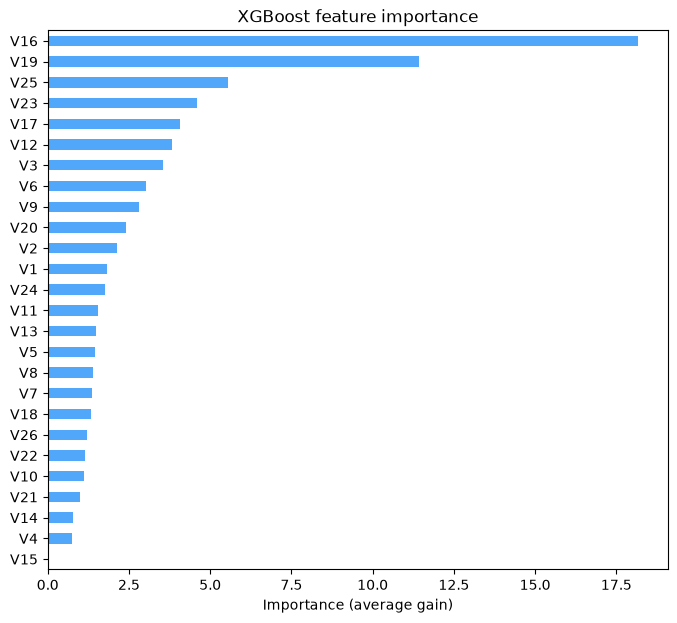

Top five most important features:
V16    18.17
V19    11.43
V25     5.55
V23     4.59
V17     4.08


In [17]:
##### YOUR CODE STARTS #####
import matplotlib.pyplot as plt

# 'gain' = average improvement of the loss brought by the splits on this feature
importance = pd.Series(bst.get_score(importance_type='gain')).reindex(X.columns, fill_value=0)

importance.sort_values().plot(kind='barh', figsize=(8, 7), color='#51A7F9')
plt.xlabel('Importance (average gain)')
plt.title('XGBoost feature importance')
plt.show()

print('Top five most important features:')
print(importance.sort_values(ascending=False).head(5).round(2).to_string())
##### YOUR CODE ENDS #####

<font color='red'> **(Homework exercise 2- d)** Train Adaptive Boosting, Gradient Boosting and a simple KNN model from sklearn (KNeighborsClassifier) on the same training data and evaluate on the same test data. For each model use the default hyperparameters (e.g. `n_estimators` or `n_neighbors`). If you do not want to use default parameters, you can use `cross_val_score` to pick the best values for the hyperparameters using training data. Compare the performance of these three models and XGBoost and draw conclusions in a separate text cell  **(1.5 points)** </font>

In [18]:
%%time
# AdaBoostClassifier
##### YOUR CODE STARTS #####
from sklearn.ensemble import AdaBoostClassifier

ada = AdaBoostClassifier(random_state=42).fit(X_train, y_train)
results.append(report('AdaBoost', y_test, ada.predict(X_test)))
##### YOUR CODE ENDS #####

AdaBoost: test accuracy 0.661, macro F1 0.571
CPU times: total: 266 ms
Wall time: 270 ms


In [19]:
%%time
# GradientBoostingClassifier
# might take considerable time if trained with default number of n_estimators
##### YOUR CODE STARTS #####
from sklearn.ensemble import GradientBoostingClassifier

gb = GradientBoostingClassifier(random_state=42).fit(X_train, y_train)
results.append(report('Gradient Boosting', y_test, gb.predict(X_test)))
##### YOUR CODE ENDS #####

Gradient Boosting: test accuracy 0.707, macro F1 0.505
CPU times: total: 2.59 s
Wall time: 2.74 s


In [20]:
%%time
# KNeighborsClassifier
##### YOUR CODE STARTS #####
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# KNN works with distances, so features on large scales (e.g. V22 ~ 100) dominate the small ones (~1-2).
# The default model on raw features, and the same default model after scaling the features:
knn = KNeighborsClassifier().fit(X_train, y_train)
results.append(report('KNN (raw features)', y_test, knn.predict(X_test)))

knn_scaled = make_pipeline(StandardScaler(), KNeighborsClassifier()).fit(X_train, y_train)
results.append(report('KNN (scaled features)', y_test, knn_scaled.predict(X_test)))

pd.DataFrame(results).set_index('model')
##### YOUR CODE ENDS #####

KNN (raw features): test accuracy 0.571, macro F1 0.355


KNN (scaled features): test accuracy 0.671, macro F1 0.456
CPU times: total: 375 ms
Wall time: 199 ms


,test accuracy,macro F1
model,,
XGBoost,0.732,0.508
AdaBoost,0.661,0.571
Gradient Boosting,0.707,0.505
KNN (raw features),0.571,0.355
KNN (scaled features),0.671,0.456


<font color='red'> How these models compare with each other and to XGBoost? Can you try to elaborate on this difference? Please formulate your thoughts concisely and if possible use your own words:  </font>

In [21]:
# Write your very concise comment here:
# All models beat the trivial baseline (always predicting the largest class: accuracy 0.586).
# - XGBoost has the best test accuracy (0.732), Gradient Boosting is close (0.707). Both build trees one after another,
#   each new tree correcting the remaining errors of the previous ones. XGBoost adds row/feature subsampling and
#   early stopping on the validation set, which probably explains its small advantage over plain Gradient Boosting.
# - AdaBoost has lower accuracy (0.661) but the best macro F1 (0.571): after each round it gives more weight to the
#   misclassified examples, which are often the rare classes, so it treats them better than the log-loss based
#   boosters, whose loss is dominated by the large classes.
# - KNN is the weakest model (0.571 on raw features). It uses all 26 features with equal weight in the distance, so
#   irrelevant features and features on large scales dominate. Scaling the features helps (0.671), but it still
#   cannot pick the informative features (V16, V19, ...) as the trees do.
# - All models struggle with the rare classes 1 and 3 (9 and 3 test examples), so macro F1 stays around 0.5.
#   The test set is small, so differences of a few points are only a few examples.

## Homework exercise 3: Kaggle in-class to predict COVID-19 mortality (4 points)
<font color='red'> In this exercise we will see how well ensembles work in the real-life problems. Here we are going to work with data from COVID-19 patients, and more specifically we will attempt to predict patient mortality based on clinical information. To this end, we have created a corresponding Kaggle in-class competition: https://www.kaggle.com/t/2efe55246b6646cb96a59bfb822e4d98 (this is invitation link). Follow it and accept competition rules. </font>

<font color='red'> **(Homework exercise 3- a)** Getting started: Create the first sample submission using a random classifier, then upload the submission via Kaggle API or by manually uploading submission file to https://www.kaggle.com/competitions/ml-ut-2026-covid-19-mortality-prediction/overview. Report your score. **(0.5 points)** </font>

In [ ]:
import pandas as pd
import numpy as np
import random

<font color='red'> Load `train.csv` and `test.csv` from https://www.kaggle.com/competitions/ml-ut-2026-covid-19-mortality-prediction/overview

In [ ]:
##### YOUR CODE STARTS #####
...
##### YOUR CODE ENDS #####

<font color='red'> Insert your random guesser below:

In [ ]:
##### YOUR CODE STARTS #####
...
##### YOUR CODE ENDS #####

<font color='red'> Create a sample submission below

In [ ]:
##### YOUR CODE STARTS #####
...
##### YOUR CODE ENDS #####

<font color='red'> You can either use Kaggle API below to submit submission file or download file and submit it manually to Kaggle via web interface. </font>

<font color='red'> To be able to use Kaggle API:

1. Open https://www.kaggle.com/settings/api
2. Under **API Tokens**, press **Generate New Token**. Give it a name such as `ml-course` and
   copy the token that appears - you will not be shown it again.
3. In Colab, click the **key icon** in the left sidebar (Secrets) and add one secret:
   * `KAGGLE_API_TOKEN` - the token you just copied

   Switch on **Notebook access**.

Secrets live in your Google account, not in the notebook: you do this once and every Colab
notebook you open afterwards can use it, including your homework. If you ever need to revoke it,
go back to the same settings page and expire that one token. </font>

In [ ]:
import os
from google.colab import userdata

os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")

<font color='red'> Assuming that you have accepted the rules of the competition, you should be able to make a submission using the following code: </font>

In [ ]:
!kaggle competitions submit -c ml-ut-2026-covid-19-mortality-prediction -f sample_submission.csv -m "Random guess submission"

<font color='red'> What was the score you received? Please add a screenshot from Kaggle that clearly shows your score. </font>

In [ ]:
# Report your result here:


<font color='red'> **(Homework exercise 3- b)** Take off: make two more submissions with at least two different ensemble models we have studied. Make sure to perform all necessary data pre-processing steps to accommodate the requirements of these ensemble models (e.g. data imputation and restructuring). To get full points, shortly summarise your pre-processing, models you have selected and rational behind this choice, and finally report your scores. **(2 points)** </font>

In [ ]:
##### YOUR CODE STARTS #####
...
##### YOUR CODE ENDS #####

<font color='red'> Summarise your pre-processing steps, models selected (why these?): </font>

In [ ]:
# Add your comment here:


<font color='red'> Report scores of your two models and upload screenshots from Kaggle that clearly show each score </font>

In [ ]:
# Report your result here:


<font color='red'> **(Homework exercise 3- c)** Reaching superiority: tune the above models or train a new one (does not have to be ensemble) such that you beat Ms.Smart (`ms_smart.csv`) baseline. If one or both of your models from 3-b are already superior to Ms.Smart, then you should beat them instead. In order to claim the point in this exercise, describe the model, data pre-processing steps and report your score (which should be higher than Ms Smart's and your previous' models). **(1.5 points)** </font>

In [ ]:
##### YOUR CODE STARTS #####
...
##### YOUR CODE ENDS #####

<font color='red'> Summarise your pre-processing steps, models selected (why these?), and the "special sauce" (what you changed compared to 3-b) below: </font>

In [ ]:
# Add your comment here:


<font color='red'> What was the score you received? Please add a screenshot from Kaggle that clearly shows your score. </font>

In [ ]:
# Add your comment here:


# Bonus exercises
*(NB, these are optional exercises!)*


##Bonus exercise 1 (1 bonus point): Interim Champion

<font color='red'> If at any point of time your submission lended at the top of the **public leaderboard** from the Kaggle competition (Exercise 3), take a screenshot of this  achievement before it is too late and somebody else did not knock it off. Post this screenshot below (add a picture). Describe your solution below (do not have to write too much, just the main idea). You can only get this point once.

In [ ]:
# Add your comment here:


##Bonus exercise 2 (up to 3 bonus points): Top Perfomer Challenge

<font color='red'> You are encouraged to compete for the top three places in the Kaggle competition described in Exercise 3. So, **3 points** for the first place, **2 points** for the second place and **1.5 points** for the third place.

<font color='red'> To receive the bonus points, you must finish in the top three of the **private leaderboard**. The end of the competition is 15.11.2026 23:59:59.
Remember that you can make only **20 submissions per day**, so start early.</font>

## Bonus exercise 3 (up to 3 bonus points depending on presentation): Discrete AdaBoost from scratch



<font color='red'> In the class we have discussed a simplified version of the AdaBoost, the goal of this task is to implement an unabrdiged version of the Discrete AdaBoost classifier following the instructions from the paper [Friedman et al (2000)](https://hastie.su.domains/Papers/AdditiveLogisticRegression/alr.pdf). In a nutshell, AdaBoost classifier assigns initial weights to training examples, fits a weak classifier, and updates the data and classifier weights based on classification accuracy. The process is repeated for each weak estimator. The final strong classifier combines weak classifiers with different weights.</font>

<font color='red'> Implement AdaBoost classifier.

Tips:

- use `DecisionTreeClassifier` from `sklearn` as a weak classifier
- avoid division by zero
- pay attention to the format of data labels.</font>



In [ ]:
class AdaBoost:
  def __init__(self, n_estimators=50):
    self.n_estimators = n_estimators
    self.estimator_weights = []
    self.models = []

  def fit(self, X, y):
    ##### YOUR CODE STARTS #####
    ...
    ##### YOUR CODE ENDS #####

  def predict(self, X):
    ##### YOUR CODE STARTS #####
    ...
    ##### YOUR CODE ENDS #####



<font color='red'> Test your model on the dataset from exercise 3. Report accuracy on the test set and observe how the performance changes with the different number of estimators.</font>

In [ ]:
##### YOUR CODE STARTS #####
...
##### YOUR CODE ENDS #####

<font color='red'> Use sklearn implementation of AdaBoost classifier with the same parameters as you used for your implementation. Report accuracy on the test set as well. </font>

In [ ]:
##### YOUR CODE STARTS #####
...
##### YOUR CODE ENDS #####

<font color='red'> Report difference in results, if there are any. Explain why sklearn's model behaves differently, you might want to take a look at sklearn's [code](https://github.com/scikit-learn/scikit-learn/blob/093e0cf14/sklearn/ensemble/_weight_boosting.py#L341) :)</font>

<font color='red'> Your answer:</font>

# Comments (optional feedback to the course instructors)
Here, please, leave your comments regarding the practice session, possibly answering the following questions:

* how much time did you spend on this homework?
* was it too hard/easy for you?
* what would you suggest to add or remove?
* anything else you would like to tell us

Your comments:

# <font color='red'>  End of the homework. Please don't delete this cell.</font>